In [23]:
import numpy as np
import matplotlib.pyplot as plt

In [24]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Exercise
*   두 개의 noisy image를 각각 f1, f2로 불러오고 적절한 restoration(denoising)을 수행해보자.항목 추가

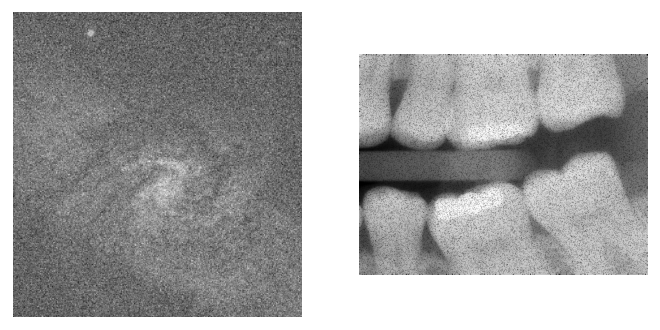

In [25]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')

plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2,cmap='gray')
plt.axis('off')
plt.show()



*   복원코드를 직접 작성해보기.



In [26]:
SS = 3
ss = int((SS-1)/2)
std_eta = 16

r_mean = np.zeros(np.shape(f2))
r_median = np.zeros(np.shape(f2))
r_amean = np.zeros(np.shape(f2))

for x in range(ss,np.size(f2,0)-ss):
    for y in range(ss,np.size(f2,1)-ss):

        Sxy = f2[x-ss:x-ss+SS,y-ss:y-ss+SS]

        # 1. Arithmetic Mean
        r_mean[x,y] = np.mean(Sxy)

        # 2. Median
        r_median[x,y] = np.median(Sxy)

        # 3. Adaptive local noise reduction
        std_Sxy = np.std(Sxy)

        if std_Sxy == 0:
            r_amean[x,y] = np.mean(Sxy)
        else:
            ratio = min(
                (std_eta*std_eta)/(std_Sxy*std_Sxy), 1
            )
            r_amean[x,y] = (
                f2[x,y] - ratio*(f2[x,y]-np.mean(Sxy))
            )



*   복원된 f2를 시각화하기





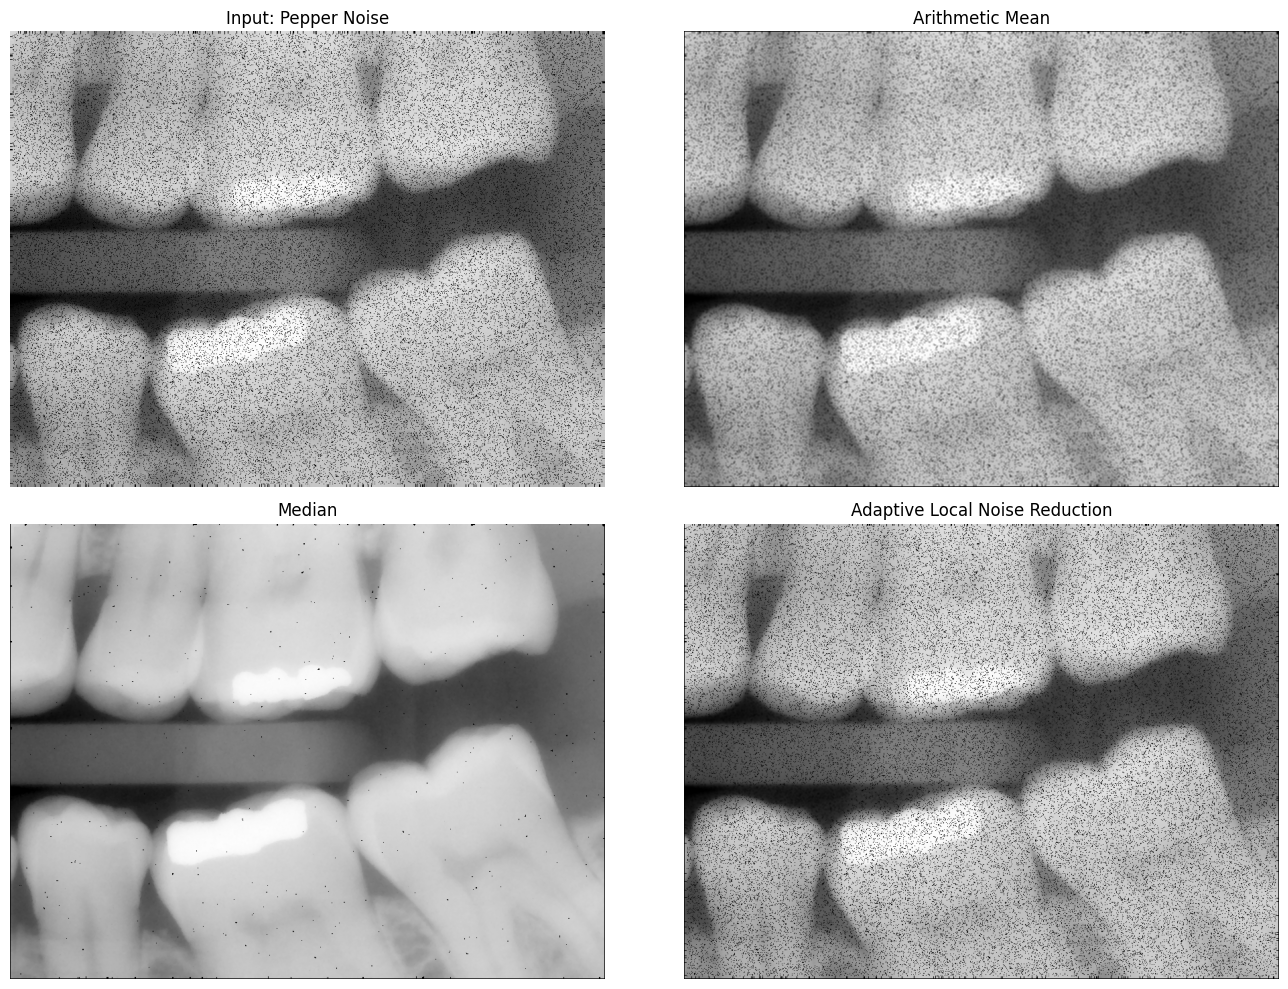

In [27]:
plt.figure(figsize=(14, 10))

images = [f2, r_mean, r_median, r_amean]
titles = [
    'Input: Pepper Noise',
    'Arithmetic Mean',
    'Median',
    'Adaptive Local Noise Reduction'
]

for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

결과: Median이 검은 점을 가장 효과적으로 제거했고, Mean은 흐려짐이 나타났으며, Adaptive는 잡음이 많이 남았다.



*   복원된 f2를 그림파일로 저장하기




In [28]:
plt.imsave('dental-mean.png',r_mean,cmap='gray')
plt.imsave('dental-median.png',r_median,cmap='gray')
plt.imsave('dental-adaptive.png',r_amean,cmap='gray')